# FireSight: Predicting Next-Day Wildfire Spread from Google Earth Engine Data

**Problem.** Satellites show where a wildfire is burning today. Responders need to know where it will burn *tomorrow*. Given today's active-fire mask and 11 environmental layers (64 km x 64 km at 1 km resolution), we predict which pixels will be burning the next day.

**Objectives.**
1. Build a clean, leakage-free pixel dataset from the Earth Engine-derived Next Day Wildfire Spread data.
2. Engineer spatial and physics-informed features (upwind fire, distance to fire, wind vectors, slope, dryness).
3. Compare 5 tuned ML models against a persistence baseline on the real, imbalanced test set.
4. Explain the drivers with SHAP and build a digital twin for wind and climate-warming what-if scenarios.

Run order: `python -m src.eda`, `python -m src.train`, `python -m src.report`, `python -m src.twin` (each step is reproduced below).

In [1]:
import json, pandas as pd
from IPython.display import Image, display
from src.data import download, build_table, n_samples
from src.features import FEATURES, BASELINE_FEATURES, engineer
from src.config import OUT_DIR, FIG_DIR
pd.set_option('display.width', 160)

## 1. Dataset
The **Next Day Wildfire Spread** dataset (Huot et al., 2022) was built in **Google Earth Engine** from MODIS active fire (MOD14A1), VIIRS NDVI, SRTM elevation, GRIDMET weather and drought, and GPWv4 population. We download the public zarr copy (no Kaggle login needed). `gee/export_fire_features.js` rebuilds the same inputs in Earth Engine for any region (example: Margalla Hills, Pakistan).

In [2]:
download()
{s: n_samples(s) for s in ['train', 'eval', 'test']}

{'train': 14979, 'eval': 1877, 'test': 1689}

## 2. Missing values and class balance
`FireMask = -1` marks cloud or missing observations. These pixels are **removed** from training and evaluation. Input layers have no NaNs, but outliers are clipped to physically plausible ranges and any NaN would be median-imputed (`src/features.py: clean`).

In [3]:
pd.read_csv(OUT_DIR / 'eda_splits.csv').round(3)

,split,tiles,pixels,next_day_fire_%,label_missing_%,prev_fire_%,prev_missing_%,nan_values_in_inputs
0,train,14979,61353984,1.073,2.349,0.821,1.093,0
1,eval,1877,7688192,1.334,2.443,0.960,1.396,0
2,test,1689,6918144,1.219,2.753,0.942,1.234,0


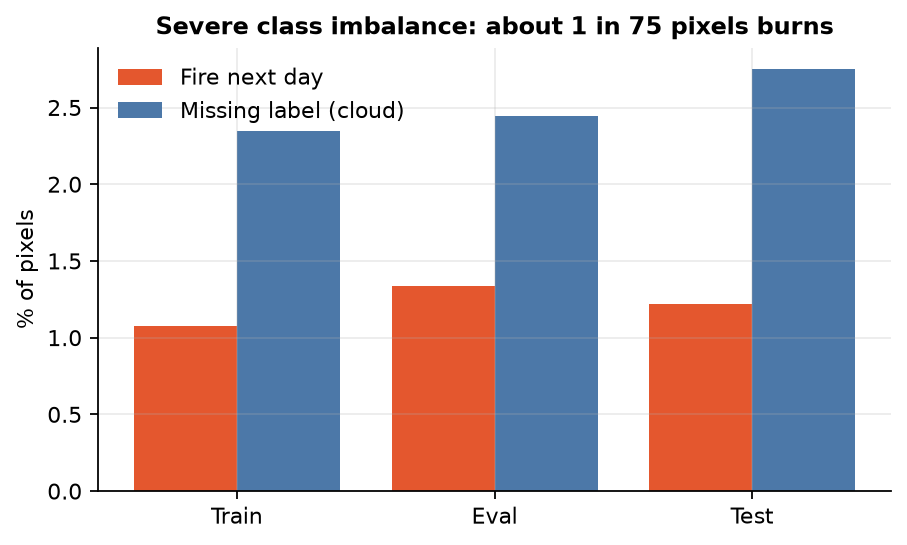

In [4]:
display(Image(FIG_DIR / 'eda_class_balance.png'))

## 3. Feature engineering
12 original inputs (11 layers + today's fire) plus 12 engineered features:

| Feature | Idea |
|---|---|
| fire_density_3/7/15 | share of burning pixels within 3, 7, 15 km |
| dist_to_fire | km to nearest active fire (Euclidean distance transform) |
| upwind_fire_2/5 | fire density sampled 2 and 5 km **upwind** using each pixel's wind direction |
| wind_u, wind_v | wind vector components (direction as numbers, no 0/360 jump) |
| temp_range | daily max - min temperature |
| slope | terrain slope from the elevation gradient |
| dryness | NDVI x energy release component (fuel amount x dryness) |
| fire_front_wind | wind speed x upwind fire |

In [5]:
sample = build_table('eval', mode='balanced', limit=200)
sample[FEATURES].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
elevation,44944.0,1103.777,789.554,0.000,386.000,1035.000,1747.000,3735.000
th,44944.0,171.436,62.059,0.000,129.117,161.628,217.596,360.000
vs,44944.0,4.007,1.556,0.000,2.907,3.917,4.706,10.394
tmmn,44944.0,282.415,5.660,250.000,278.998,282.878,285.873,300.054
tmmx,44944.0,299.418,6.420,250.000,295.299,299.738,303.472,314.648
sph,44944.0,0.005,0.002,0.000,0.003,0.005,0.006,0.019
pr,44944.0,0.148,1.262,0.000,0.000,0.000,0.000,35.143
pdsi,44944.0,-0.120,2.820,-5.737,-2.523,-0.778,1.546,9.164
NDVI,44944.0,4326.671,1971.186,-2000.000,2761.000,3989.000,5810.000,9674.000
population,44944.0,11.962,108.626,0.000,0.000,0.033,1.053,3000.000


## 4. Exploratory data analysis

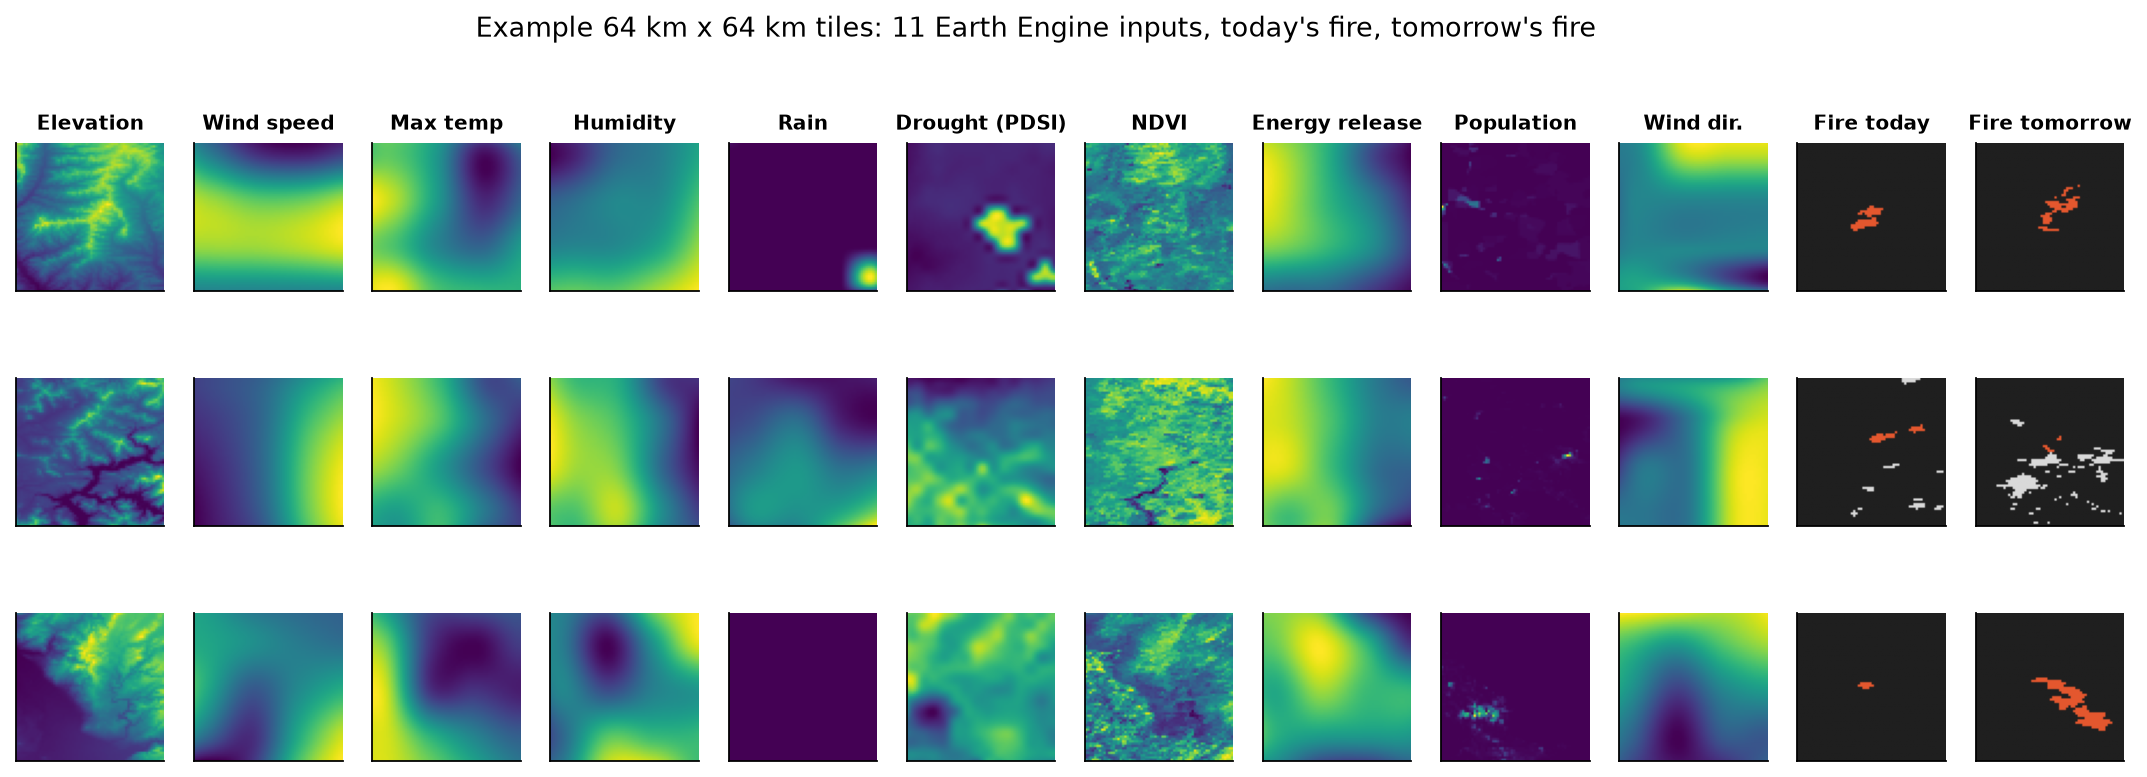

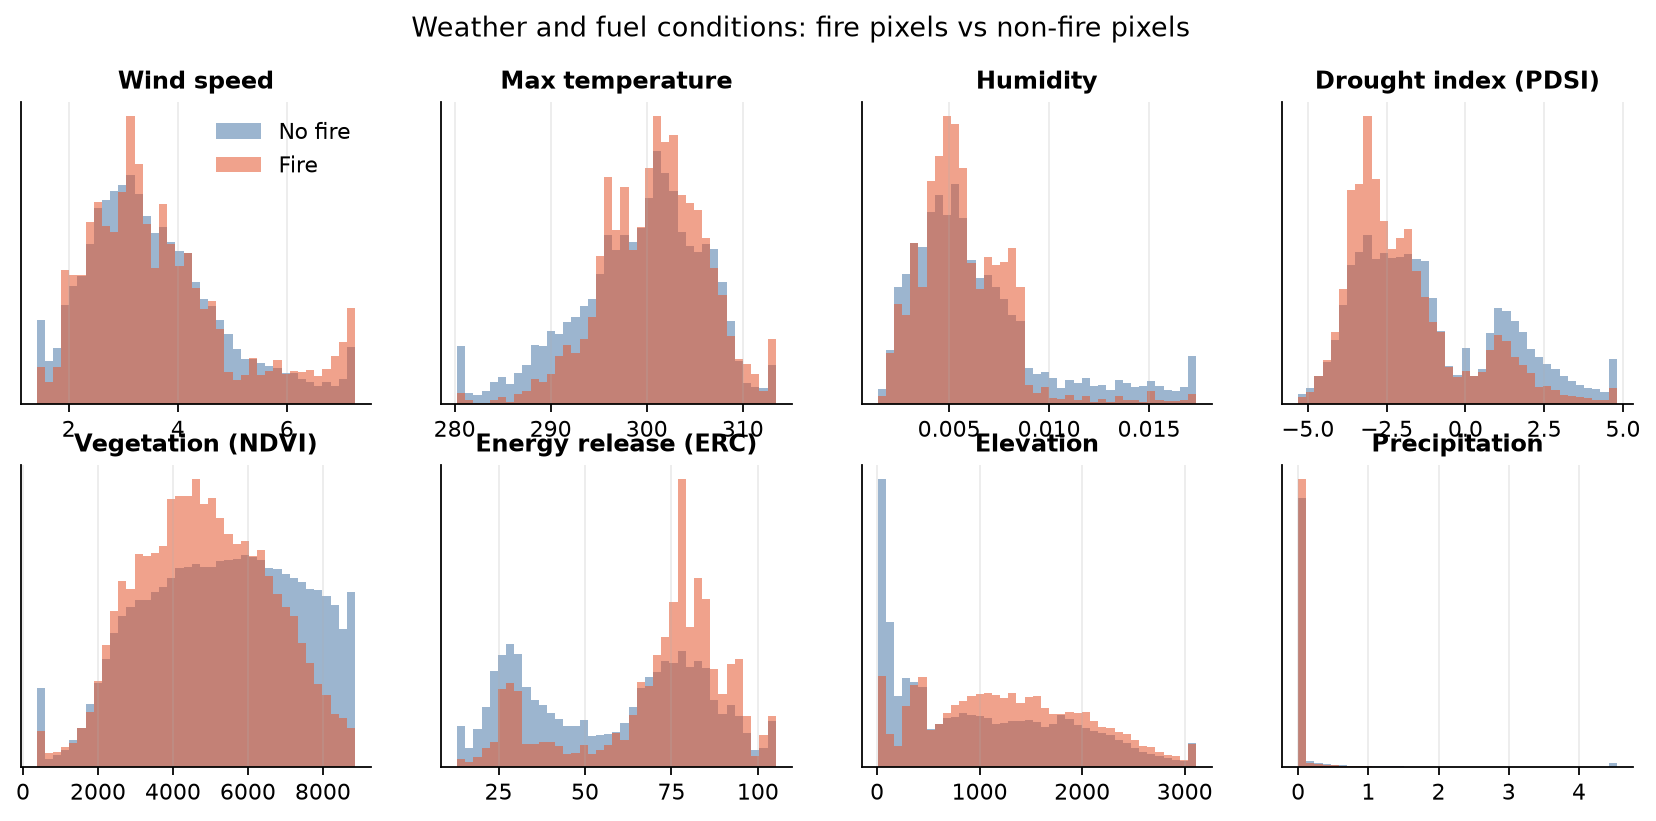

In [6]:
display(Image(FIG_DIR / 'eda_sample_tiles.png'))
display(Image(FIG_DIR / 'eda_distributions.png'))

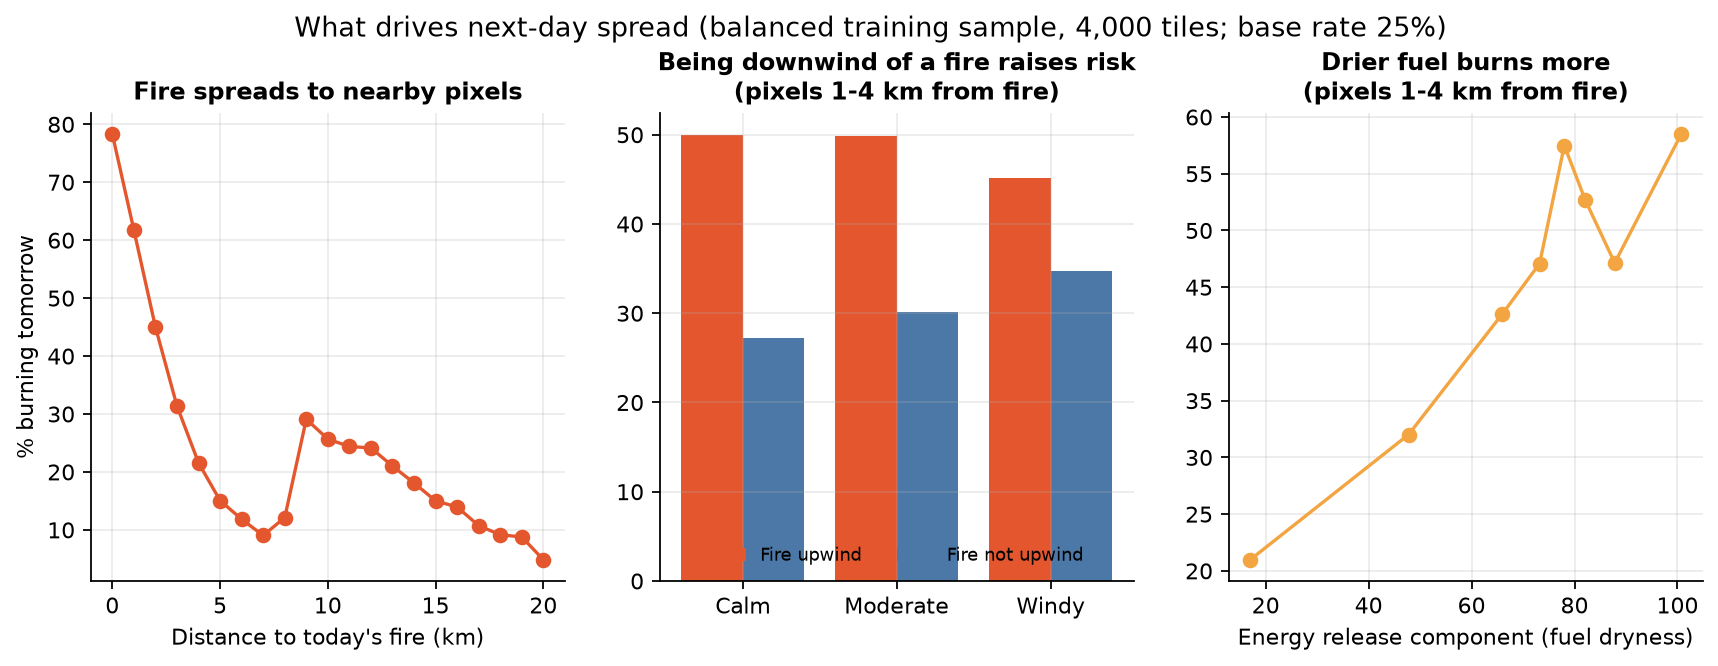

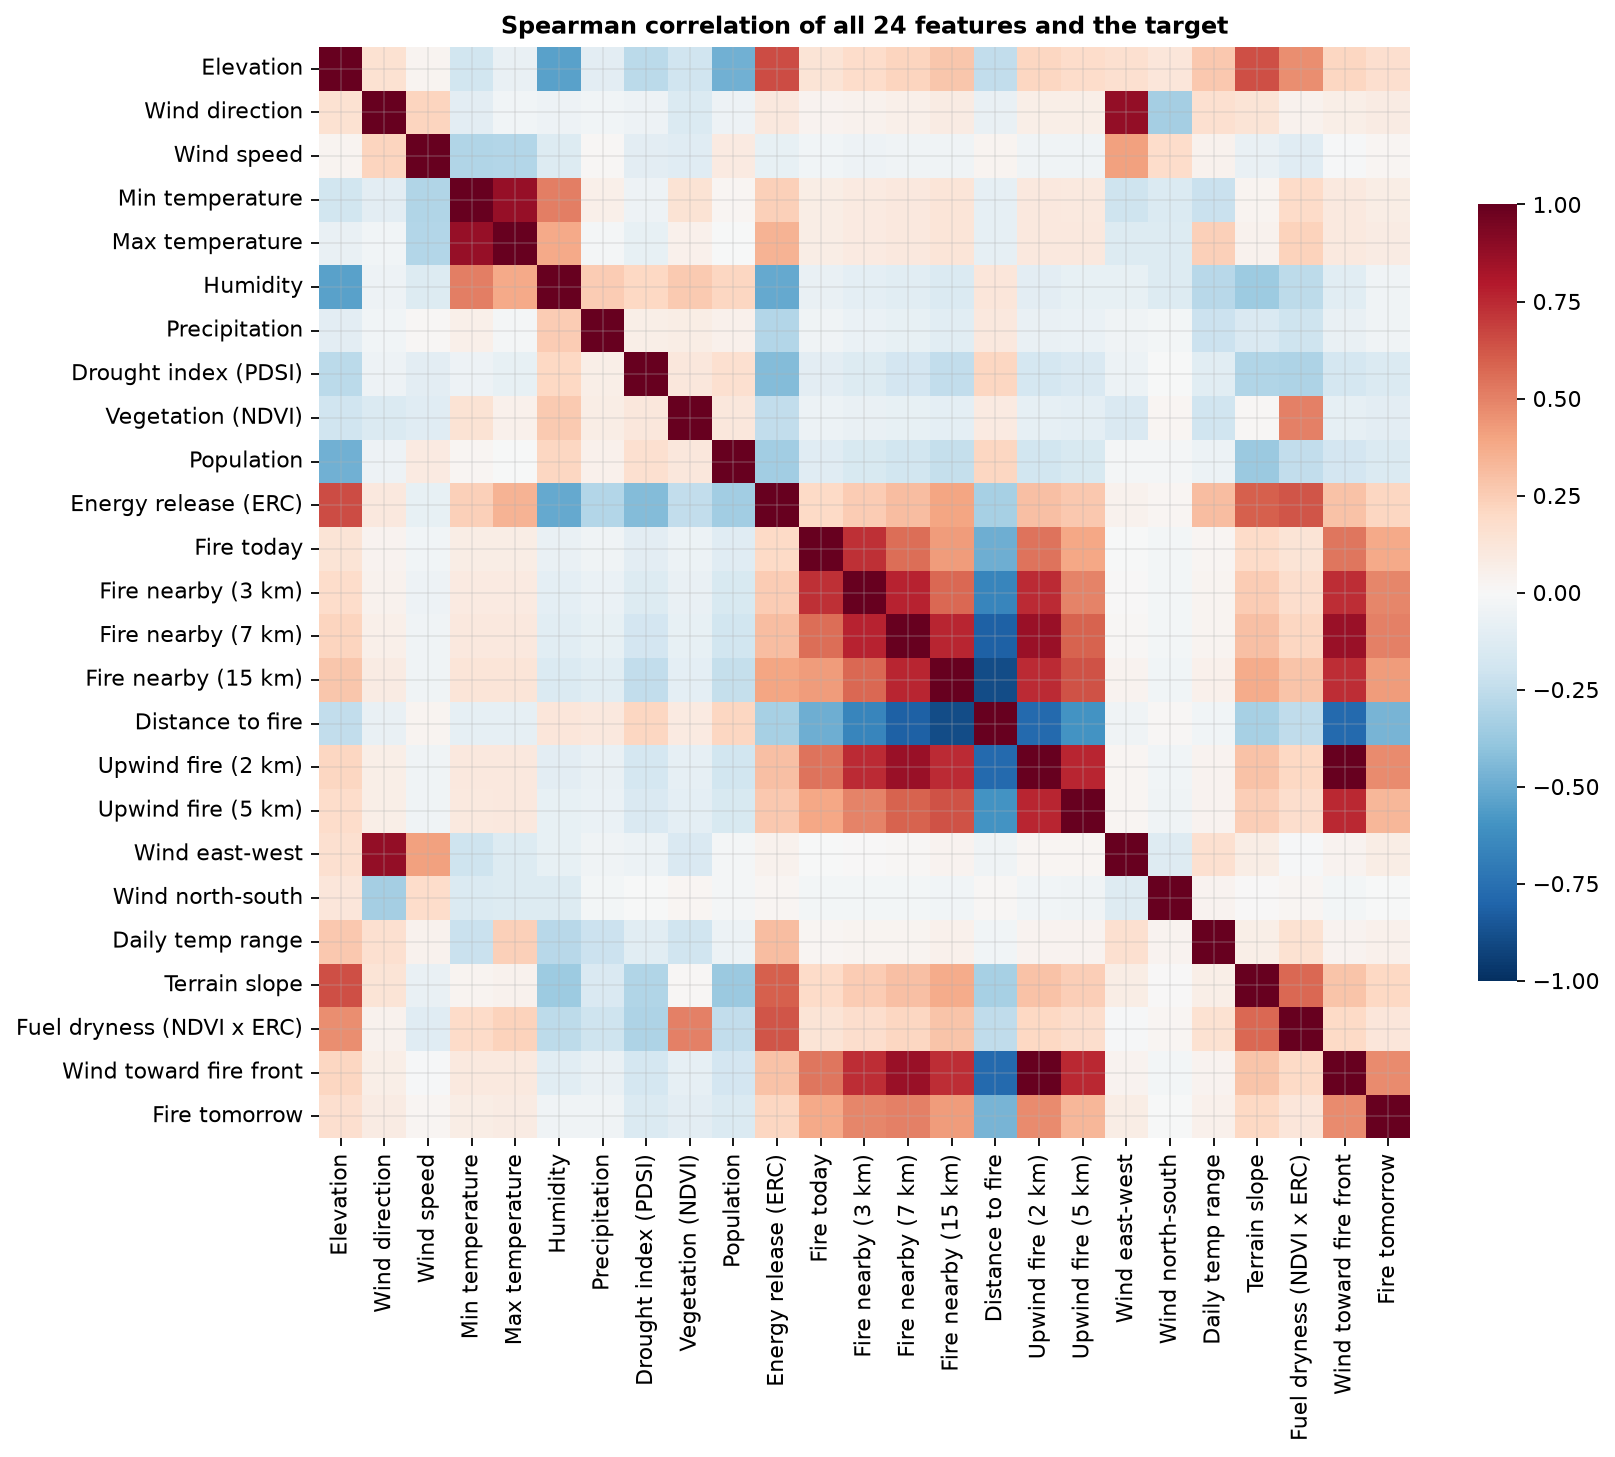

In [7]:
display(Image(FIG_DIR / 'eda_spread_drivers.png'))
display(Image(FIG_DIR / 'eda_correlation.png'))

In [8]:
pd.read_csv(OUT_DIR / 'eda_summary_stats.csv', index_col=0)

,mean,std,min,50%,max
Elevation,1077.485,838.353,0.000,975.000,4123.000
Wind direction,204.198,68.754,0.000,212.075,360.000
Wind speed,3.618,1.314,0.000,3.372,12.000
Min temperature,283.869,6.477,250.000,284.222,301.678
Max temperature,299.652,6.811,250.000,300.554,320.000
Humidity,0.006,0.003,0.000,0.005,0.025
Precipitation,0.192,1.052,0.000,0.000,40.316
Drought index (PDSI),-1.379,2.283,-7.969,-1.927,9.195
Vegetation (NDVI),5197.416,2008.150,-2000.000,5220.000,9906.000
Population,16.844,141.694,0.000,0.049,3000.000


## 5. Models and hyper-parameter tuning
* **Models:** Logistic Regression, Random Forest, XGBoost, LightGBM, MLP neural network, and a persistence baseline.
* **Standardization:** `StandardScaler` inside the LR and MLP pipelines (trees do not need it).
* **Imbalance:** balanced training sample (all fire pixels + 3 non-fire per fire pixel, half of them near the fire).
* **Tuning:** `RandomizedSearchCV`, 3-fold **GroupKFold by fire tile** (stops pixels of the same fire leaking between folds), scored by average precision.
* **Threshold:** chosen to maximise F1 on the separate eval split; all metrics on the full test split.

Training takes about 30-60 minutes on a laptop. Set `RETRAIN = True` to run it here; otherwise the saved results load.

In [9]:
RETRAIN = False
if RETRAIN:
    from src.train import main as train_main
    train_main()
R = json.load(open(OUT_DIR / 'results.json'))
R['data']

{'train_rows': 2633062,
 'train_fire_rate': 0.2500017090368552,
 'eval_rows': 7500385,
 'eval_fire_rate': 0.013678497837111028,
 'test_rows': 6727699,
 'test_fire_rate': 0.012534894917266661,
 'n_features': 24,
 'features': ['elevation',
  'th',
  'vs',
  'tmmn',
  'tmmx',
  'sph',
  'pr',
  'pdsi',
  'NDVI',
  'population',
  'erc',
  'prev_fire',
  'fire_density_3',
  'fire_density_7',
  'fire_density_15',
  'dist_to_fire',
  'upwind_fire_2',
  'upwind_fire_5',
  'wind_u',
  'wind_v',
  'temp_range',
  'slope',
  'dryness',
  'fire_front_wind']}

In [10]:
pd.DataFrame({m: r['best_params'] for m, r in R['models'].items() if r['best_params']}).T

,logisticregression__C,logisticregression__class_weight,max_depth,max_features,min_samples_leaf,n_estimators,colsample_bytree,learning_rate,min_child_weight,subsample,min_child_samples,num_leaves,reg_lambda,subsample_freq,mlpclassifier__alpha,mlpclassifier__batch_size,mlpclassifier__hidden_layer_sizes,mlpclassifier__learning_rate_init
Logistic Regression,0.984674,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Random Forest,NaN,NaN,23,sqrt,37,157,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
XGBoost,NaN,NaN,9.0,NaN,NaN,391.0,0.528206,0.123879,2.294868,0.996885,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LightGBM,NaN,NaN,NaN,NaN,NaN,585.0,0.984955,0.163736,NaN,0.846993,47.0,206.0,9.307783,1.0,NaN,NaN,NaN,NaN
MLP (Neural Net),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000133,512,"[128, 64, 32]",0.001619


## 6. Evaluation and comparative analysis

In [11]:
pd.read_csv(OUT_DIR / 'results_table.csv').round(3)

,Model,Accuracy,Precision,Recall,F1,AUC-PR,ROC-AUC,CV AUC-PR,Threshold,Time (s)
0,Persistence baseline,0.985,0.357,0.273,0.309,0.106,0.633,NaN,0.500,0.0
1,Logistic Regression,0.978,0.272,0.453,0.340,0.227,0.901,0.640,0.443,14.9
2,Random Forest,0.976,0.264,0.491,0.343,0.258,0.876,0.745,0.459,618.3
3,XGBoost,0.977,0.258,0.445,0.326,0.228,0.866,0.832,0.416,156.7
4,LightGBM,0.975,0.237,0.465,0.314,0.215,0.845,0.848,0.328,959.0
5,MLP (Neural Net),0.974,0.198,0.362,0.256,0.116,0.790,0.742,0.568,259.4


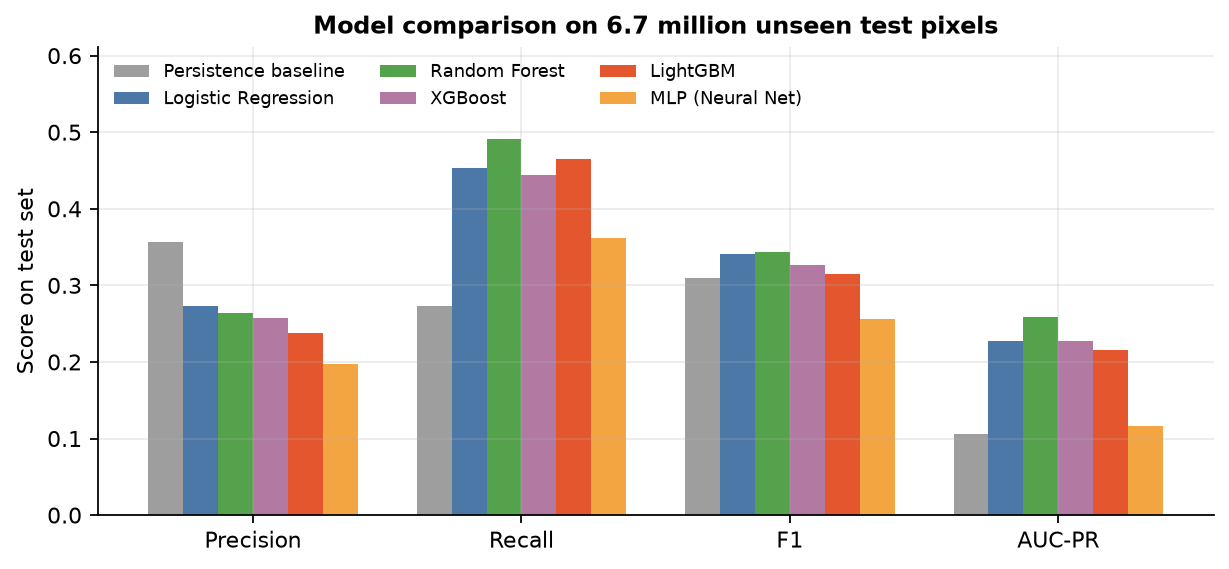

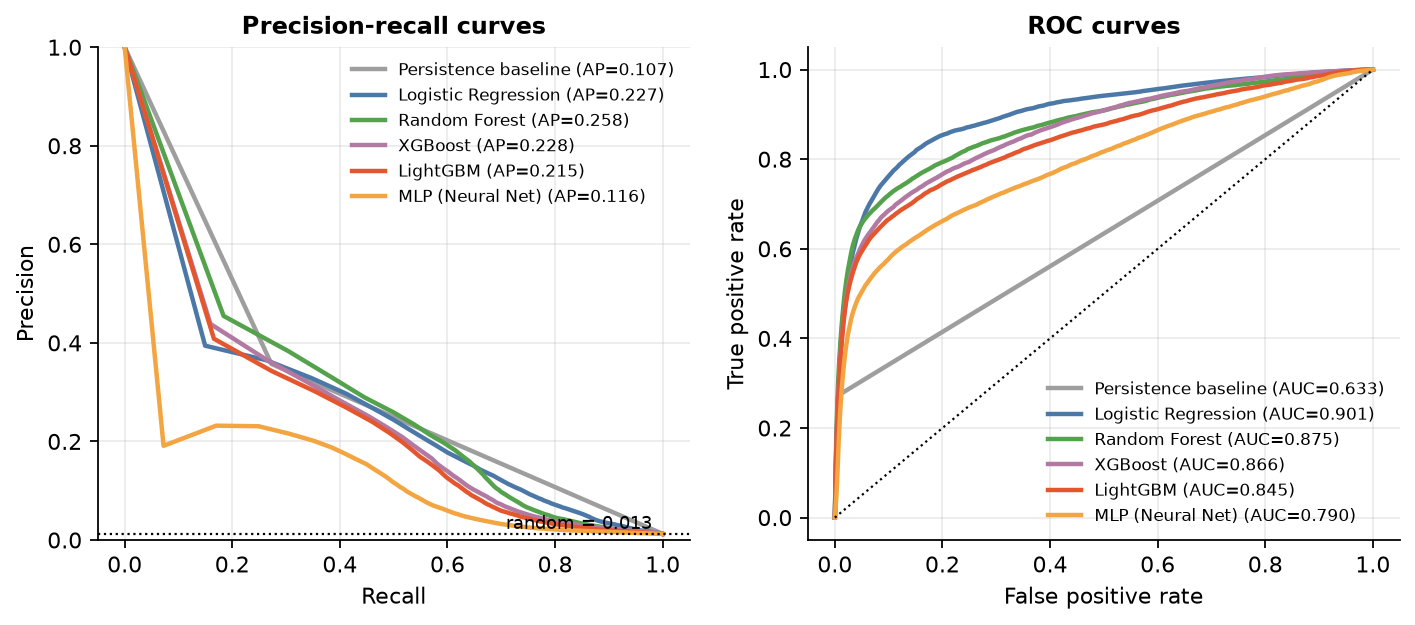

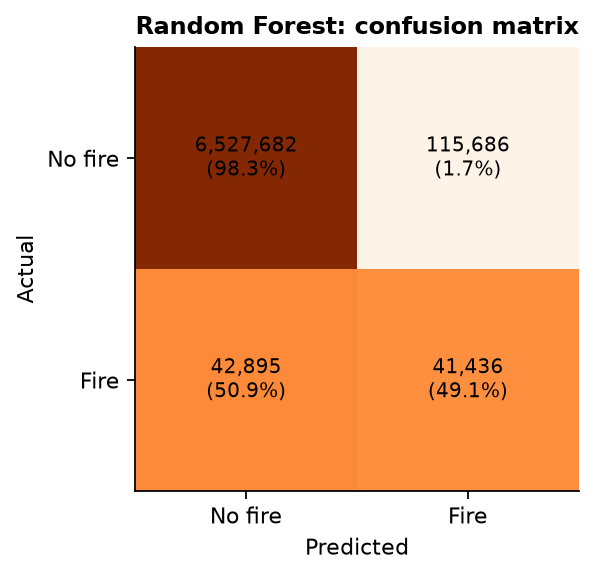

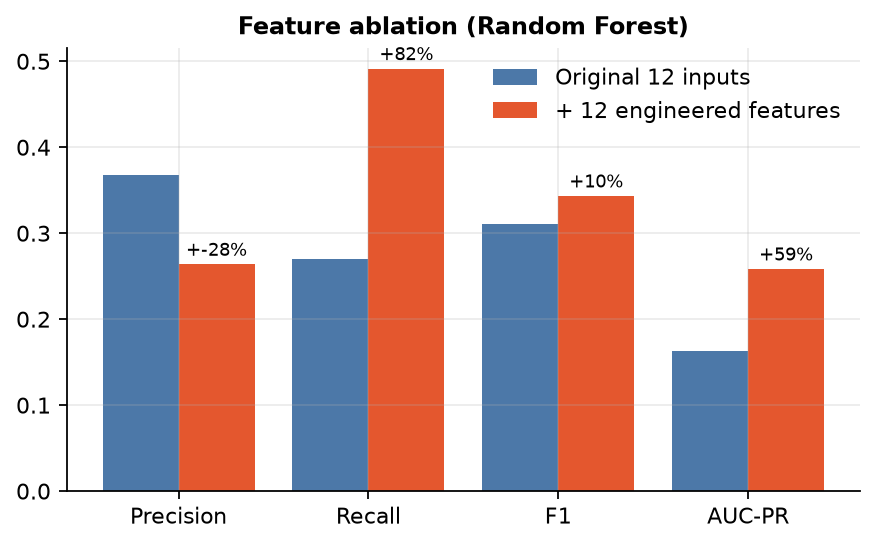

In [12]:
for f in ['results_metrics', 'results_curves', 'results_confusion', 'results_ablation']:
    display(Image(FIG_DIR / f'{f}.png'))

## 7. Explainability (SHAP)

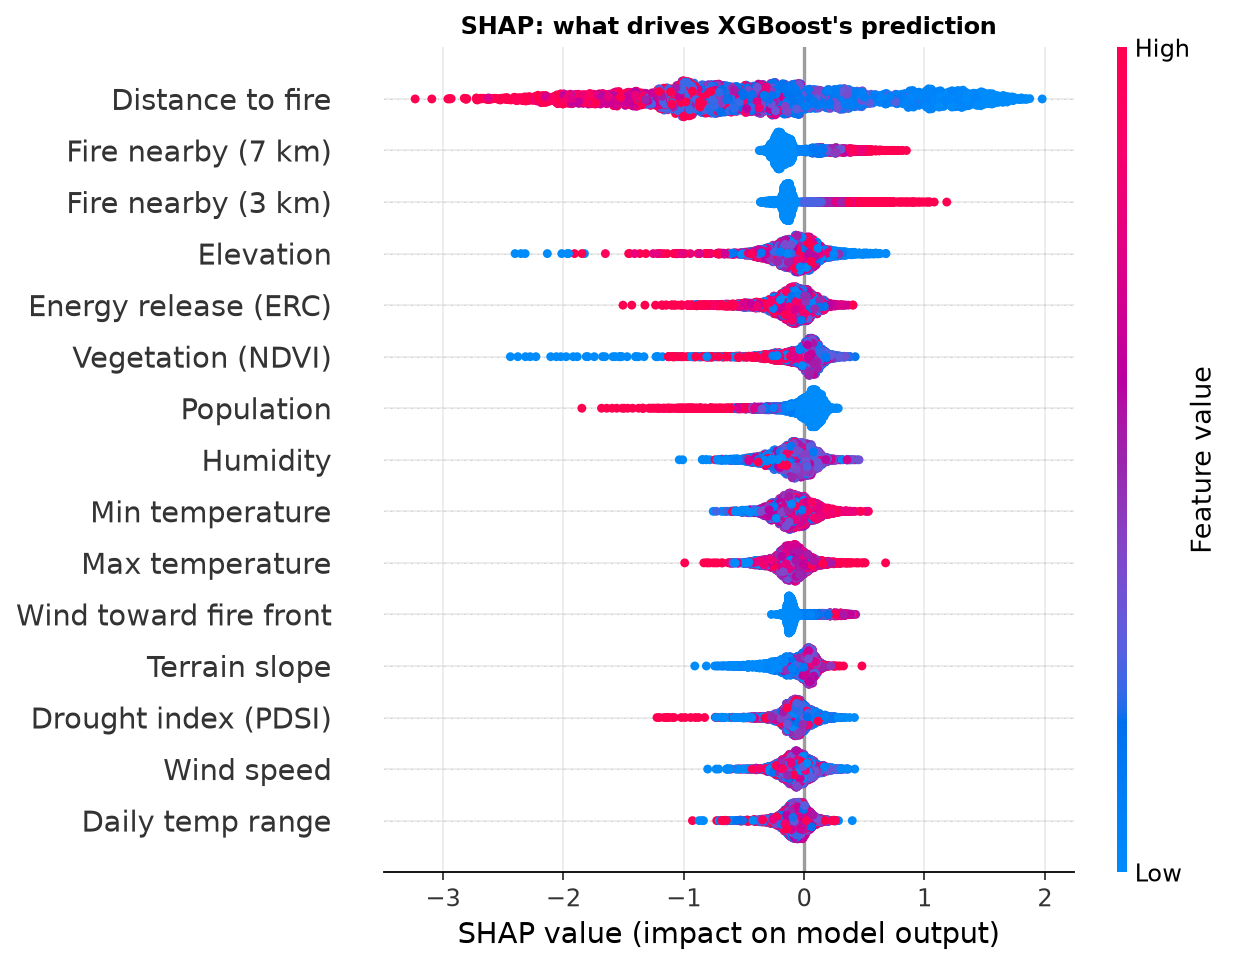

,0
Max temperature,0.141093
Min temperature,0.142135
Humidity,0.145825
Population,0.146710
Vegetation (NDVI),0.147342
Energy release (ERC),0.168503
Elevation,0.170227
Fire nearby (3 km),0.184115
Fire nearby (7 km),0.205593
Distance to fire,0.869804


In [13]:
display(Image(FIG_DIR / 'results_shap.png'))
pd.read_csv(OUT_DIR / 'shap_importance.csv', index_col=0).tail(10)

## 8. Prediction maps

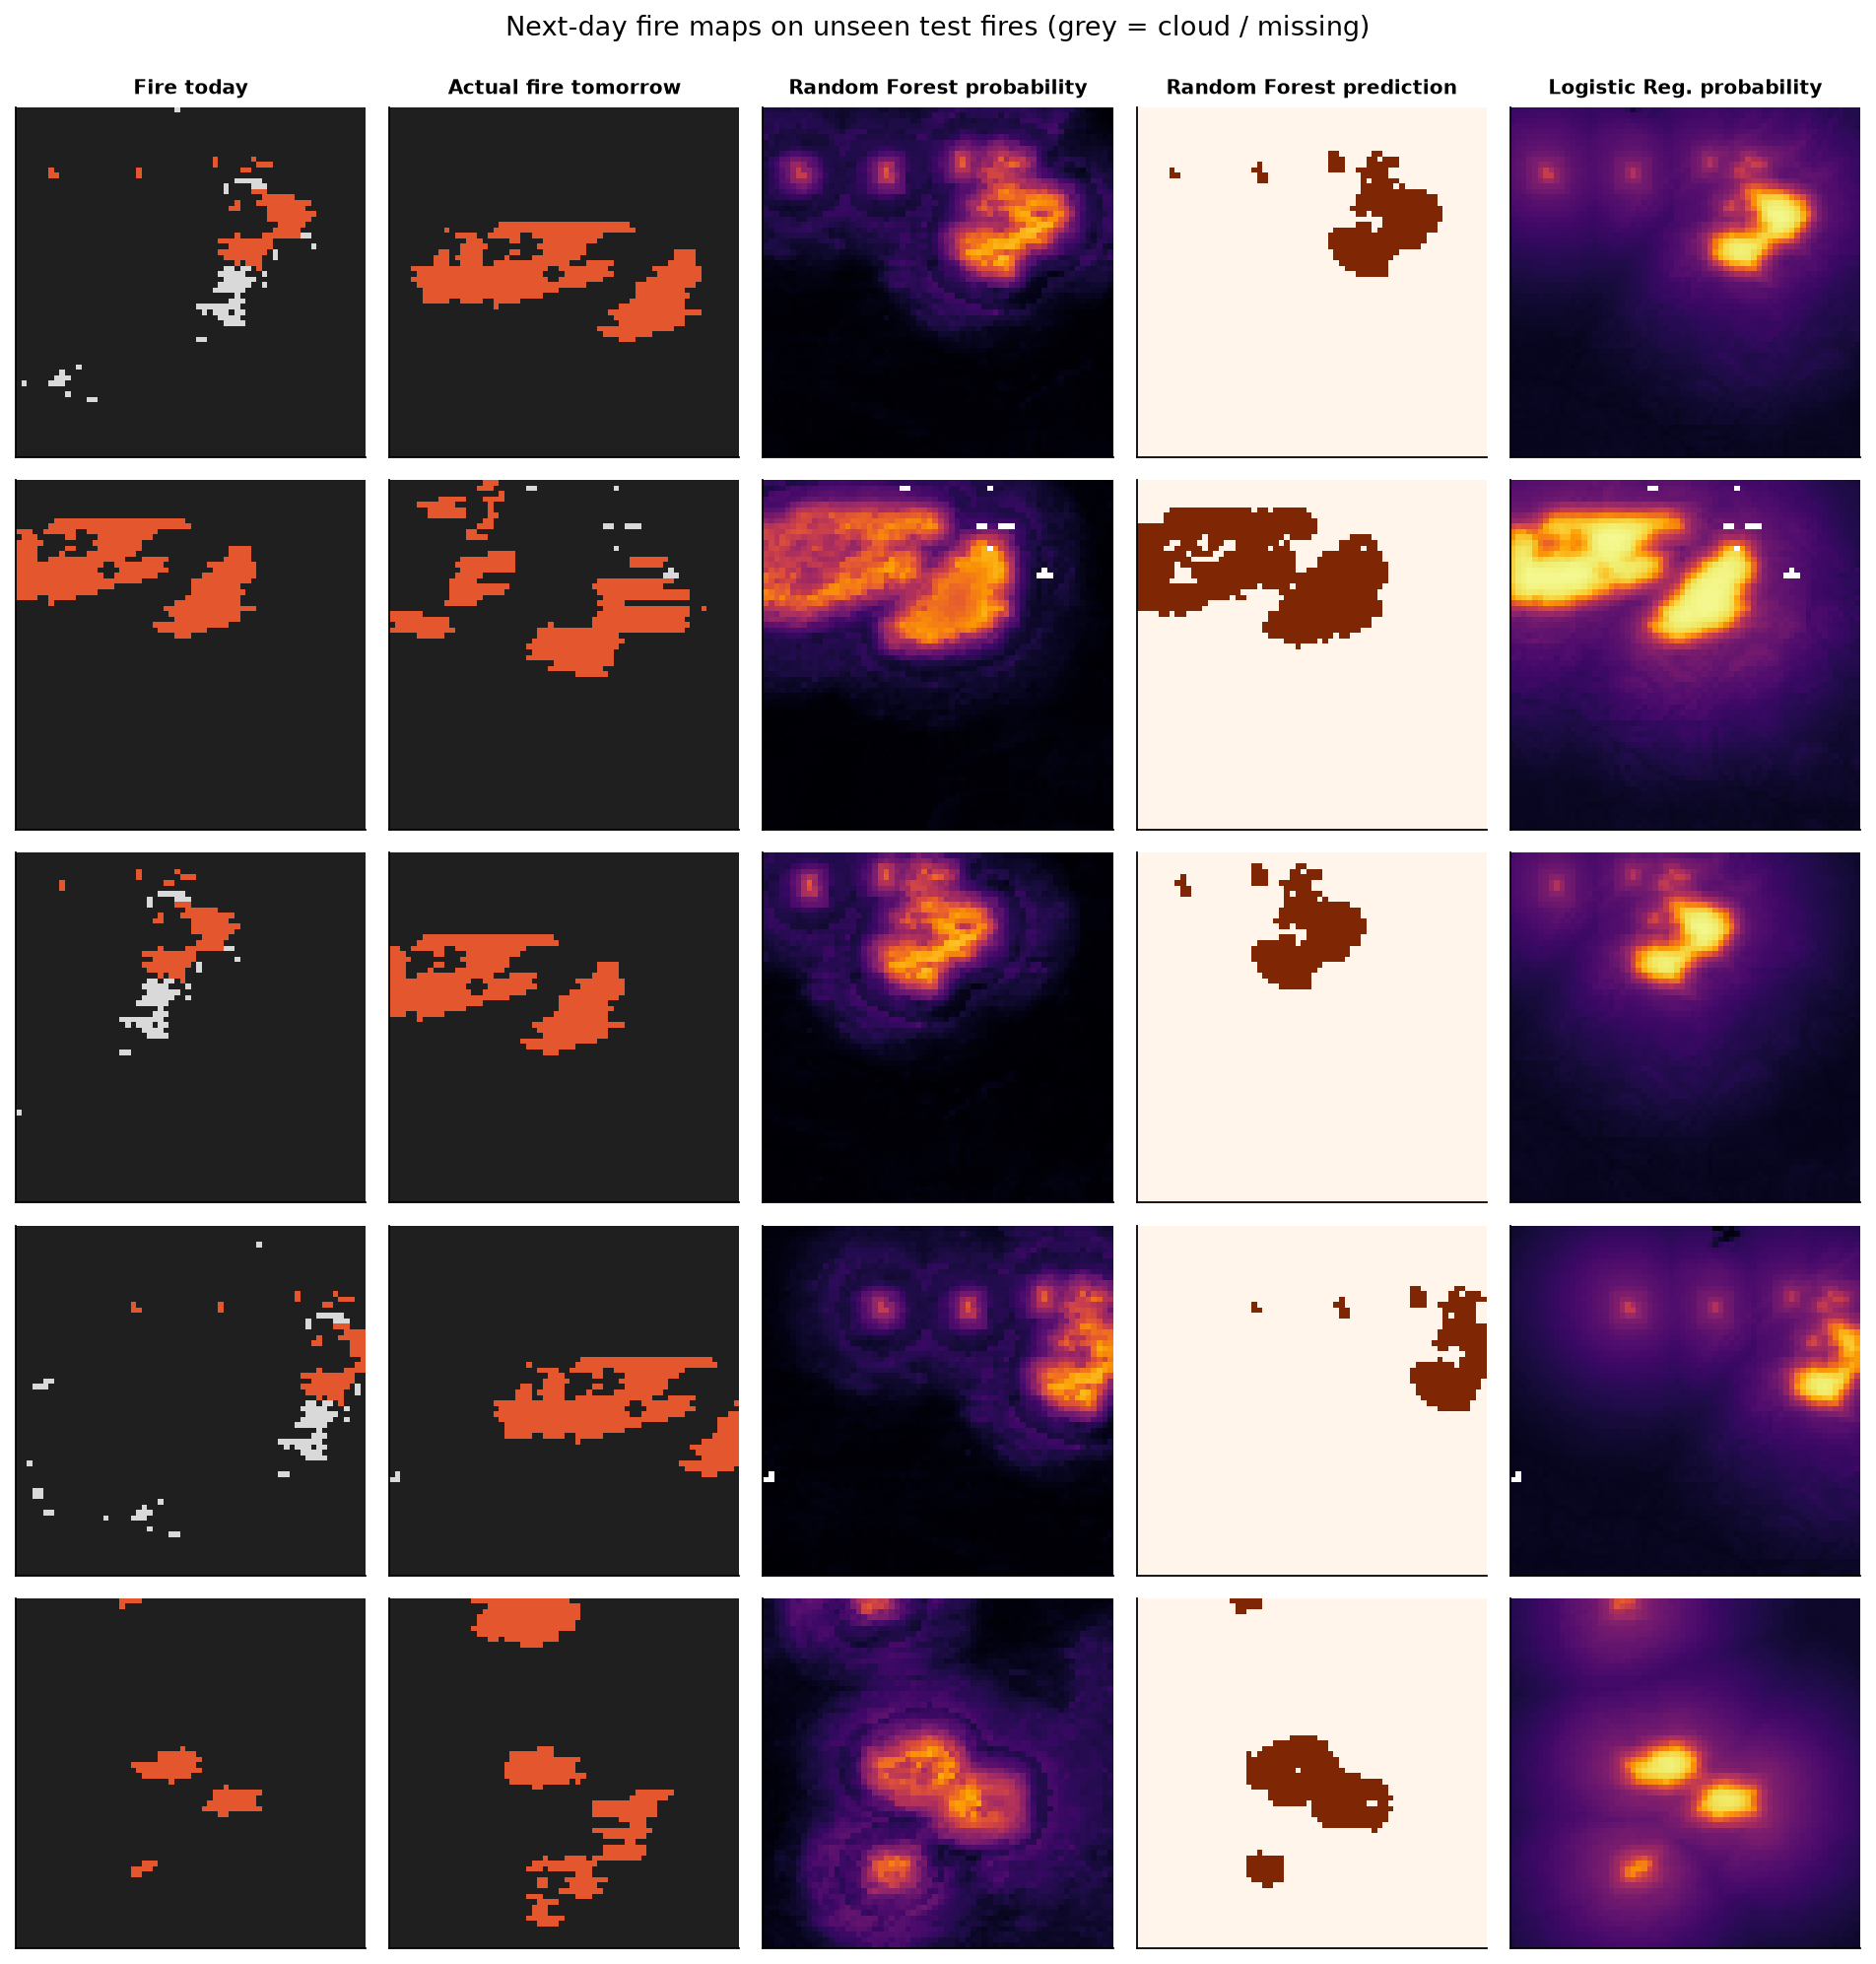

In [14]:
display(Image(FIG_DIR / 'results_maps.png'))

## 9. Digital twin: wind and climate what-if scenarios
For real test fires we rotate or scale the wind, or apply +2 C / +4 C warming (higher temperature and ERC, lower humidity, more negative PDSI), recompute all features and predict again. The interactive version is on the project website.

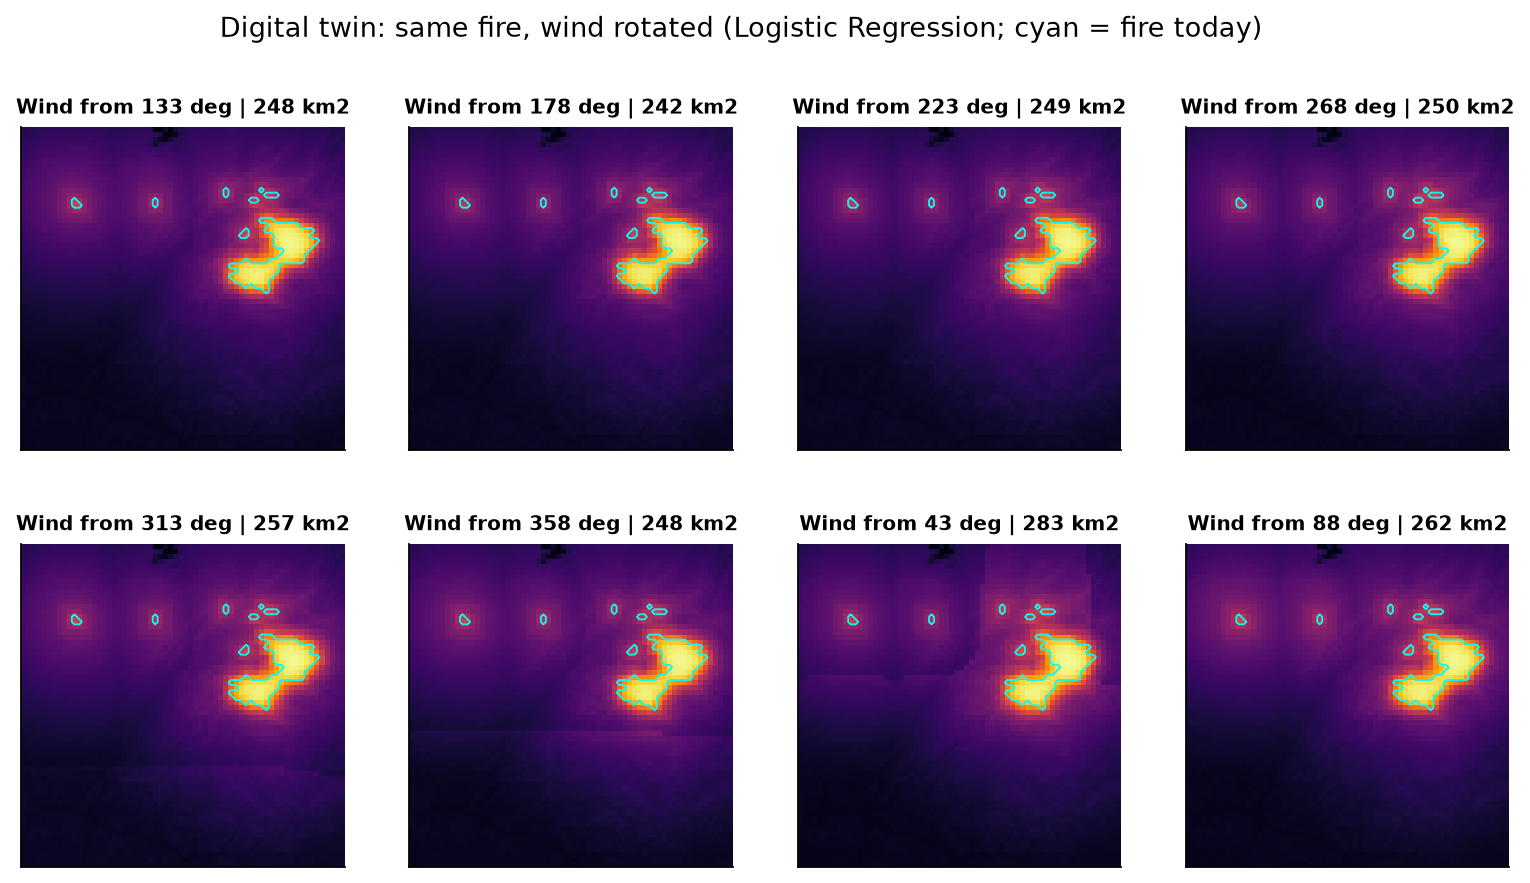

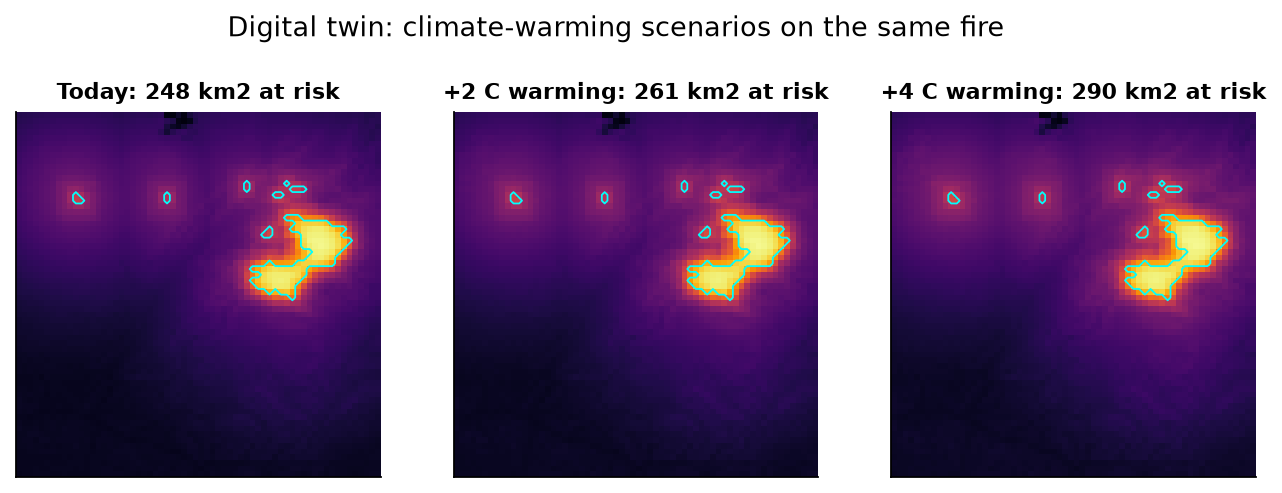

{'Today': 240.25, '+2 C warming': 258.25, '+4 C warming': 289.25}

In [15]:
display(Image(FIG_DIR / 'twin_wind.png'))
display(Image(FIG_DIR / 'twin_climate.png'))
json.load(open(OUT_DIR / 'twin_summary.json'))

## 10. Conclusion
See the research paper (`paper/FireSight_Paper.pdf`) for the full discussion.